In [1]:
import pandas as pd
import numpy as np
import json
import os
import shutil
from PIL import Image
import matplotlib.pyplot as plt
import matplotlib.patches as patches
from IPython.display import display, clear_output
import ipywidgets as widgets
from google.colab import drive

drive.mount('/content/drive')

BASE          = '/content/drive/MyDrive/CDT_Dataset'
IMAGE_FOLDER  = f'{BASE}/images'
HUMAN_FOLDER  = f'{BASE}/images_human_fixed'
RESULT_FOLDER = f'{BASE}/results'
os.makedirs(HUMAN_FOLDER, exist_ok=True)

Mounted at /content/drive


In [10]:
with open(f'{BASE}/labels/ccss_labels_v2.json') as f:
    llm_labels = json.load(f)

final_df = pd.read_csv(
    f'{BASE}/labels/ccss_labels_final.csv'
)


progress_path = f'{BASE}/labels/human_review_progress.json'
if os.path.exists(progress_path):
    with open(progress_path) as f:
        reviewed = json.load(f)
    print(f'มี progress เดิม: {len(reviewed)} รูป')
else:
    reviewed = {}

review_list = final_df['filename'].tolist()

remaining = [
    f for f in review_list
    if f not in reviewed
]

print(f'รูปทั้งหมด     : {len(review_list)}')
print(f'Review แล้ว   : {len(reviewed)}')
print(f'ยังไม่ได้ review: {len(remaining)}')

มี progress เดิม: 6601 รูป
รูปทั้งหมด     : 6602
Review แล้ว   : 6601
ยังไม่ได้ review: 1


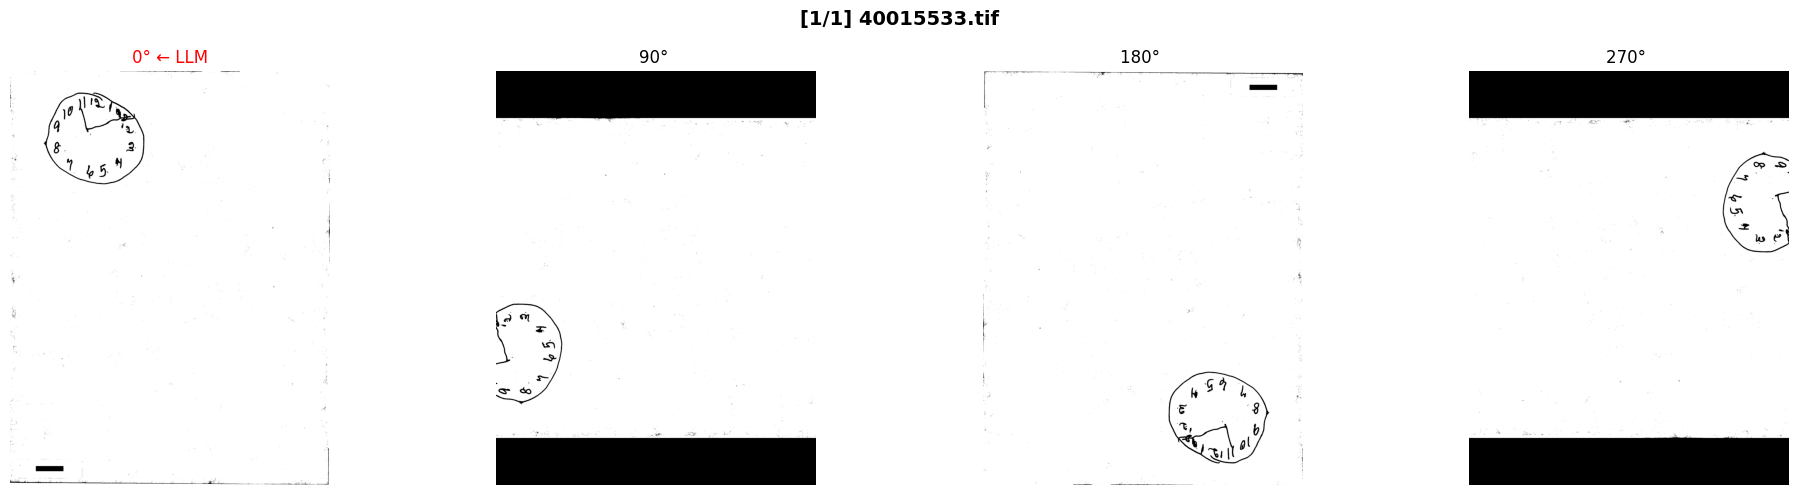


LLM Label (confidence=0.92):
  A (digit_count)       : 2
  B (worst_quadrant)    : 2
  C (spatial)           : 2
  D (hands_present)     : 2
  E (hands_placement)   : 2
  Total                 : 10
  LLM หมุนรูป          : 0°

เลือกทิศที่ถูกต้อง:


RadioButtons(description='ทิศที่ถูก:', options=(('0°', 0), ('90°', 90), ('180°', 180), ('270°', 270)), style=D…


คะแนนแต่ละ domain (0-2):


BoundedIntText(value=2, description='A (digit_count):', layout=Layout(width='300px'), max=2, style=Description…

BoundedIntText(value=2, description='B (worst_quadrant):', layout=Layout(width='300px'), max=2, style=Descript…

BoundedIntText(value=2, description='C (spatial):', layout=Layout(width='300px'), max=2, style=DescriptionStyl…

BoundedIntText(value=2, description='D (hands_present):', layout=Layout(width='300px'), max=2, style=Descripti…

BoundedIntText(value=2, description='E (hands_placement):', layout=Layout(width='300px'), max=2, style=Descrip…

Text(value='', description='Note:', layout=Layout(width='400px'), placeholder='หมายเหตุ (optional)')

Review Done!


In [11]:
current_idx   = [0]
human_results = dict(reviewed)

def get_llm_label(filename):
    data = llm_labels.get(filename, {})
    scores = data.get('scores', {})
    return {
        'A': scores.get('digit_count', '?'),
        'B': scores.get('worst_quadrant_error', '?'),
        'C': scores.get('spatial_arrangement', '?'),
        'D': scores.get('hands_present', '?'),
        'E': scores.get('hands_placement', '?'),
        'confidence': data.get('confidence', '?'),
        'rotation'  : data.get('best_rotation', 0),
    }

def save_progress():
    with open(progress_path, 'w') as f:
        json.dump(human_results, f, indent=2)

    rows = []
    for filename, data in human_results.items():
        row = final_df[
            final_df['filename'] == filename
        ].iloc[0].to_dict()
        row['domain_A']      = data['scores']['A']
        row['domain_B']      = data['scores']['B']
        row['domain_C']      = data['scores']['C']
        row['domain_D']      = data['scores']['D']
        row['domain_E']      = data['scores']['E']
        row['total_score']   = sum(data['scores'].values())
        row['dementia_risk'] = row['total_score'] < 6
        row['rotation_fixed']= data['rotation']
        row['reviewed_by']   = 'human'
        rows.append(row)

    if rows:
        pd.DataFrame(rows).to_csv(
            f'{BASE}/labels/human_labels.csv',
            index=False
        )

def show_review_ui():
    if current_idx[0] >= len(remaining):
        print('Review Done!')
        return

    filename = remaining[current_idx[0]]
    llm      = get_llm_label(filename)
    src_path = f'{IMAGE_FOLDER}/{filename}'

    clear_output(wait=True)

    img = Image.open(src_path).convert('RGB')
    fig, axes = plt.subplots(1, 4, figsize=(20, 5))

    for i, angle in enumerate([0, 90, 180, 270]):
        rotated = img.rotate(angle, expand=False)
        axes[i].imshow(rotated)
        axes[i].set_title(
            f'{angle}° {"← LLM" if angle == llm["rotation"] else ""}',
            fontsize=12,
            color='red' if angle == llm['rotation'] else 'black'
        )
        axes[i].axis('off')
        if angle == llm['rotation']:
            for spine in axes[i].spines.values():
                spine.set_edgecolor('red')
                spine.set_linewidth(3)

    plt.suptitle(
        f'[{current_idx[0]+1}/{len(remaining)}] '
        f'{filename}',
        fontsize=14, fontweight='bold'
    )
    plt.tight_layout()
    plt.show()

    print(f'\n{"="*50}')
    print(f'LLM Label (confidence={llm["confidence"]}):')
    print(f'  A (digit_count)       : {llm["A"]}')
    print(f'  B (worst_quadrant)    : {llm["B"]}')
    print(f'  C (spatial)           : {llm["C"]}')
    print(f'  D (hands_present)     : {llm["D"]}')
    print(f'  E (hands_placement)   : {llm["E"]}')
    total = sum([
        llm['A'], llm['B'], llm['C'],
        llm['D'], llm['E']
    ] if all(isinstance(v, int)
             for v in [llm['A'], llm['B'],
                       llm['C'], llm['D'],
                       llm['E']]) else [0])
    print(f'  Total                 : {total}')
    print(f'  LLM หมุนรูป          : {llm["rotation"]}°')
    print(f'{"="*50}')

    rotation_widget = widgets.RadioButtons(
        options=[
            ('0°', 0),
            ('90°', 90),
            ('180°', 180),
            ('270°', 270),
        ],
        value=llm['rotation'],
        description='ทิศที่ถูก:',
        style={'description_width': 'initial'}
    )

    score_widgets = {}
    for domain, name in [
        ('A', 'digit_count'),
        ('B', 'worst_quadrant'),
        ('C', 'spatial'),
        ('D', 'hands_present'),
        ('E', 'hands_placement'),
    ]:
        score_widgets[domain] = widgets.BoundedIntText(
            value=llm[domain] if isinstance(
                llm[domain], int) else 1,
            min=0, max=2,
            description=f'{domain} ({name}):',
            style={'description_width': 'initial'},
            layout=widgets.Layout(width='300px')
        )

    note_widget = widgets.Text(
        placeholder='หมายเหตุ (optional)',
        description='Note:',
        layout=widgets.Layout(width='400px')
    )

    save_btn = widgets.Button(
        description='บันทึกและต่อไป',
        button_style='success',
        layout=widgets.Layout(width='200px')
    )
    skip_btn = widgets.Button(
        description='⏭ ข้าม (ใช้ LLM label)',
        button_style='warning',
        layout=widgets.Layout(width='200px')
    )
    back_btn = widgets.Button(
        description='◀ ย้อนกลับ',
        button_style='info',
        layout=widgets.Layout(width='150px')
    )

    def on_save(b):
        """บันทึก human label"""
        fname    = remaining[current_idx[0]]
        rotation = rotation_widget.value
        scores   = {
            d: score_widgets[d].value
            for d in ['A', 'B', 'C', 'D', 'E']
        }
        src = f'{IMAGE_FOLDER}/{fname}'
        dst_name = fname.replace('.tif', '.jpg')
        dst = f'{HUMAN_FOLDER}/{dst_name}'

        img_save = Image.open(src).convert('RGB')
        if rotation != 0:
            img_save = img_save.rotate(
                rotation, expand=False
            )
        img_save.save(dst, 'JPEG', quality=95)

        human_results[fname] = {
            'scores'  : scores,
            'rotation': rotation,
            'note'    : note_widget.value,
            'source'  : 'human',
        }

        save_progress()

        current_idx[0] += 1
        show_review_ui()

    def on_skip(b):
        """ข้าม ใช้ LLM label เดิม"""
        fname    = remaining[current_idx[0]]
        rotation = llm['rotation']
        scores   = {
            'A': llm['A'] if isinstance(llm['A'], int) else 1,
            'B': llm['B'] if isinstance(llm['B'], int) else 1,
            'C': llm['C'] if isinstance(llm['C'], int) else 1,
            'D': llm['D'] if isinstance(llm['D'], int) else 1,
            'E': llm['E'] if isinstance(llm['E'], int) else 1,
        }

        src = f'{IMAGE_FOLDER}/{fname}'
        dst_name = fname.replace('.tif', '.jpg')
        dst = f'{HUMAN_FOLDER}/{dst_name}'

        img_save = Image.open(src).convert('RGB')
        if rotation != 0:
            img_save = img_save.rotate(
                rotation, expand=False
            )
        img_save.save(dst, 'JPEG', quality=95)

        human_results[fname] = {
            'scores'  : scores,
            'rotation': rotation,
            'note'    : 'skipped - used LLM label',
            'source'  : 'llm',
        }

        save_progress()

        current_idx[0] += 1
        show_review_ui()

    def on_back(b):
        """ย้อนกลับรูปก่อนหน้า"""
        if current_idx[0] > 0:
            current_idx[0] -= 1
            show_review_ui()

    save_btn.on_click(on_save)
    skip_btn.on_click(on_skip)
    back_btn.on_click(on_back)

    print('\nเลือกทิศที่ถูกต้อง:')
    display(rotation_widget)

    print('\nคะแนนแต่ละ domain (0-2):')
    for domain in ['A', 'B', 'C', 'D', 'E']:
        display(score_widgets[domain])

    display(note_widget)
    display(
        widgets.HBox([save_btn, skip_btn, back_btn])
    )

show_review_ui()

In [12]:
reviewed_human = sum(
    1 for v in human_results.values()
    if v['source'] == 'human'
)
reviewed_llm = sum(
    1 for v in human_results.values()
    if v['source'] == 'llm'
)

print(f'Progress: {len(human_results)}/{len(review_list)}')
print(f'  Human review: {reviewed_human} รูป')
print(f'  ใช้ LLM      : {reviewed_llm} รูป')
print(f'  ยังเหลือ     : {len(remaining)-current_idx[0]} รูป')

Progress: 6602/6602
  Human review: 5884 รูป
  ใช้ LLM      : 718 รูป
  ยังเหลือ     : 0 รูป


In [13]:
human_df = pd.read_csv(
    f'{BASE}/labels/human_labels.csv'
)

from sklearn.model_selection import train_test_split

train_df, temp_df = train_test_split(
    human_df, test_size=0.3,
    random_state=42,
    stratify=human_df['dementia_risk']
)
val_df, test_df = train_test_split(
    temp_df, test_size=0.67,
    random_state=42,
    stratify=temp_df['dementia_risk']
)

for df, name in [
    (train_df, 'train'),
    (val_df,   'val'),
    (test_df,  'test'),
]:
    df['filename'] = df['filename'].str.replace(
        '.tif', '.jpg', regex=False
    )
    df.to_csv(
        f'{BASE}/labels/human_{name}.csv',
        index=False
    )
    print(f'human_{name}.csv: {len(df)} รูป')

human_train.csv: 4621 รูป
human_val.csv: 653 รูป
human_test.csv: 1328 รูป
